# 02. Baseline

Faithful subset of the book's workflow. Per round of repeated stratified resampling (100 rounds, 30% of patients held out), on the training patients only:

1. ANOVA filter (p < 0.01) on the 4,025 probes left by the label-free first filter.
2. Strategy **s1**: use all ANOVA genes. Strategy **s2**: keep the 30 genes with the highest random-forest importance.
3. Fit random forest, SVM and k-NN variants on the selected genes and score the held-out patients.

All workflows see the same splits, so they can be compared pairwise.

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon
from pipeline import CLASSES, anova_genes, evaluate, load_data

X, y = load_data()
print('after first filter:', X.shape)
# descriptive only (uses all labels, not used for modelling): book reports 746
print('ANOVA genes on all 94 patients:', len(anova_genes(X, y)))

after first filter: (94, 4025)
ANOVA genes on all 94 patients: 751


## Run the 100 rounds

In [2]:
scores, confusion = evaluate(X, y, n_rounds=100, seed=0, leak=False)
scores['workflow'] = scores['selection'] + '_' + scores['model']
scores.to_csv('../results/baseline_scores.csv', index=False)

cm = pd.concat({k: pd.DataFrame(v, index=CLASSES, columns=CLASSES) for k, v in confusion.items()},
               names=['selection', 'model', 'true'])
cm.to_csv('../results/baseline_confusion.csv')
print(scores.shape)

(2400, 10)


## Accuracy and balanced accuracy per workflow

In [3]:
summary = scores.groupby('workflow')[['accuracy', 'balanced_accuracy'] + CLASSES].mean()
summary['accuracy_sd'] = scores.groupby('workflow')['accuracy'].std()
summary = summary.sort_values('accuracy', ascending=False)
print('always-NEG reference accuracy:', round(y.value_counts(normalize=True).max(), 3))
summary.round(3)

always-NEG reference accuracy: 0.447


,accuracy,balanced_accuracy,NEG,BCR/ABL,ALL1/AF4,E2A/PBX1,accuracy_sd
workflow,,,,,,,
s2_knn3_z,0.852,0.847,0.830,0.866,0.997,0.695,0.057
s2_knn3_iqr,0.840,0.844,0.818,0.848,0.983,0.725,0.060
s2_knn5_z,0.839,0.806,0.837,0.855,0.987,0.545,0.061
s1_svm_C100_g0.001,0.836,0.809,0.843,0.836,0.957,0.600,0.062
s1_knn3_iqr,0.834,0.885,0.752,0.877,0.960,0.950,0.053
s2_knn5_iqr,0.825,0.791,0.827,0.837,0.967,0.535,0.065
s2_svm_C100_g0.01,0.824,0.824,0.783,0.855,0.990,0.670,0.063
s2_svm_C100_g0.001,0.822,0.824,0.779,0.854,0.980,0.685,0.063
s1_knn5_iqr,0.821,0.834,0.760,0.875,0.907,0.795,0.069


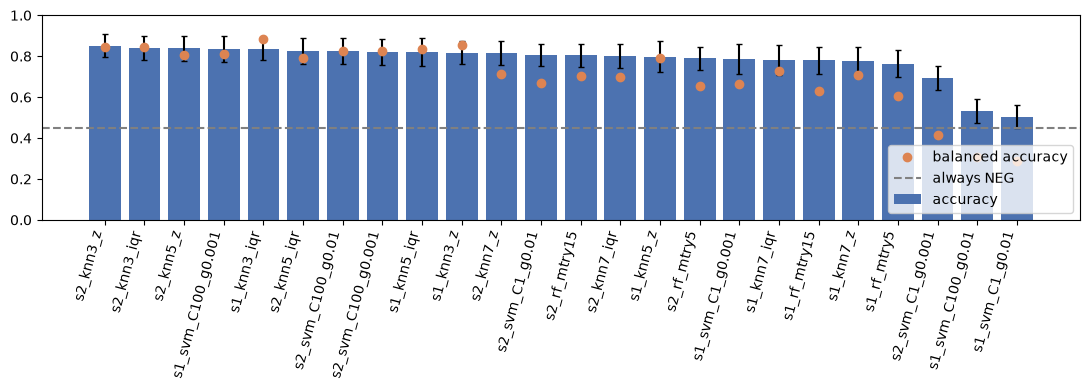

In [4]:
order = summary.index
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(order)), summary['accuracy'], yerr=summary['accuracy_sd'], color='#4c72b0', capsize=2, label='accuracy')
ax.plot(range(len(order)), summary['balanced_accuracy'], 'o', color='#dd8452', label='balanced accuracy')
ax.axhline(0.447, ls='--', color='grey', label='always NEG')
ax.set_xticks(range(len(order)), order, rotation=75, ha='right')
ax.set_ylim(0, 1)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../results/baseline_accuracy.png', dpi=120)
plt.show()

## Top workflows against the best one (paired Wilcoxon over rounds, as in the book)

In [5]:
acc = scores.pivot(index='round', columns='workflow', values='accuracy')
best = summary.index[0]
rows = []
for w in summary.index[:10]:
    p = 1.0 if w == best else wilcoxon(acc[best], acc[w]).pvalue
    rows.append((w, summary.loc[w, 'accuracy'], summary.loc[w, 'balanced_accuracy'], p))
pd.DataFrame(rows, columns=['workflow', 'accuracy', 'balanced_accuracy', 'p_vs_best']).round(3)

,workflow,accuracy,balanced_accuracy,p_vs_best
0,s2_knn3_z,0.852,0.847,1.000
1,s2_knn3_iqr,0.840,0.844,0.009
2,s2_knn5_z,0.839,0.806,0.001
3,s1_svm_C100_g0.001,0.836,0.809,0.033
4,s1_knn3_iqr,0.834,0.885,0.009
5,s2_knn5_iqr,0.825,0.791,0.000
6,s2_svm_C100_g0.01,0.824,0.824,0.000
7,s2_svm_C100_g0.001,0.822,0.824,0.000
8,s1_knn5_iqr,0.821,0.834,0.001
9,s1_knn3_z,0.817,0.855,0.000


## Selection strategy and model family

In [6]:
scores['family'] = scores['model'].str.split('_').str[0].str.replace(r'\d+', '', regex=True)
scores.groupby(['family', 'selection'])[['accuracy', 'balanced_accuracy']].mean().round(3)

accuracy  balanced_accuracy
family selection                             
knn    s1            0.805              0.800
       s2            0.829              0.783
rf     s1            0.772              0.617
       s2            0.798              0.680
svm    s1            0.665              0.517
       s2            0.786              0.683

## Per-class recall and confusion matrix of the best workflow

best by accuracy: s2_knn3_z
NEG         0.830
BCR/ABL     0.866
ALL1/AF4    0.997
E2A/PBX1    0.695
Name: s2_knn3_z, dtype: float64


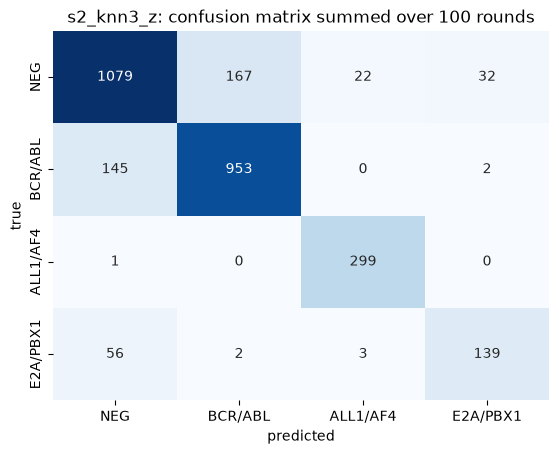

In [7]:
print('best by accuracy:', best)
print(summary.loc[best, CLASSES].round(3))

sel, model = best.split('_', 1)
m = cm.loc[(sel, model)]
sns.heatmap(m, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title(f'{best}: confusion matrix summed over 100 rounds')
plt.ylabel('true')
plt.xlabel('predicted')
plt.savefig('../results/baseline_confusion.png', dpi=120, bbox_inches='tight')
plt.show()

## Notes

**What the baseline shows**

- The ranking pattern follows the book: k-NN and SVM variants lead, random forest is lower, and the 30-gene random-forest selection (s2) is mostly ahead of using all ANOVA genes (s1). Best accuracy is `s2_knn3_z` at 0.852.
- The "best" workflow depends on the metric. `s1_knn3_iqr` has lower accuracy (0.834) but the highest balanced accuracy (0.885) and an E2A/PBX1 recall of 0.95. Accuracy is dominated by NEG and BCR/ABL; balanced accuracy weights each class equally.
- Several workflows with 0.76 to 0.81 accuracy almost never recognise E2A/PBX1 (recall 0.00 to 0.09, for example `s1_rf_mtry5`, `s2_rf_mtry5`, `s2_svm_C1_g0.01`). Accuracy alone hides this.
- Two SVMs (`s1_svm_C1_g0.01` and `s1_svm_C100_g0.01`) reach only 0.50 to 0.53 and predict almost everything as NEG. With gamma 0.01 and 751 standardised genes, the RBF kernel value is close to zero for any pair of patients, so the model falls back to the majority class. The same gamma works with 30 genes. The SVM is therefore sensitive to both gamma and the number of features.

**Limits of the comparison with the book**

- The accuracies are not like for like. This notebook uses repeated stratified resampling with a 30% hold-out; the book uses the bootstrap. The gene sets also differ (4,025 probes after the first filter and 751 after ANOVA, against 3,943 and 746). Only the ranking and the pattern should be compared, not the decimals.
- The random-forest top 30 uses scikit-learn impurity importance; the book uses permutation importance (mean decrease in accuracy). Impurity importance can favour some genes over others.
- The SVM grid has four of the book's six settings (gamma 0.0001 is left out).
- With 5 E2A/PBX1 patients and a 30% hold-out, a round tests only 1 or 2 of them, so per-class recall for this class is very coarse in a single round. It is meaningful only as an average over the 100 rounds, and it remains noisy.
- The 100 rounds share training patients, so the rounds are not independent and the paired Wilcoxon p-values are optimistic. Here most of the top workflows differ significantly from the best one, while the book found no significant differences among its top 10. Given this optimism, small accuracy differences between top workflows should not be treated as established.